# MNIST Handwritten Digit Classification

This notebook builds a feedforward neural network to classify handwritten digits (0–9) using the MNIST dataset. It covers data exploration, preprocessing, forward propagation, backpropagation, evaluation, and prediction visualization.


## 1. Import libraries
TensorFlow/Keras provides the neural-network API. NumPy handles arrays, Matplotlib visualizes images and training history, and scikit-learn provides classification metrics.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print('TensorFlow version:', tf.__version__)
np.random.seed(42)
tf.random.set_seed(42)


TensorFlow version: 2.21.0


## 2. Load the MNIST dataset
MNIST contains 60,000 training images and 10,000 test images. Each image is a 28 × 28 grayscale image and its label is a digit from 0 to 9. Keras downloads the dataset automatically the first time this cell runs (internet required).


In [2]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.mnist.load_data()

print('Training images:', X_train.shape)
print('Training labels:', y_train.shape)
print('Test images:', X_test.shape)
print('Test labels:', y_test.shape)
print('Pixel range before normalization:', X_train.min(), 'to', X_train.max())


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)
Pixel range before normalization: 0 to 255


## 3. Explore sample images
Visualizing examples helps confirm that the data and labels loaded correctly.


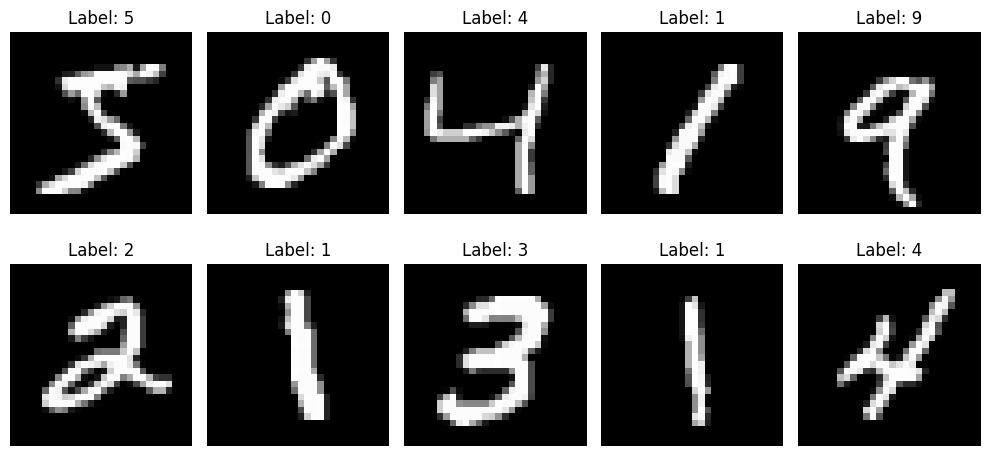

In [3]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, image, label in zip(axes.flat, X_train[:10], y_train[:10]):
    ax.imshow(image, cmap='gray')
    ax.set_title(f'Label: {label}')
    ax.axis('off')
plt.tight_layout()
plt.show()


## 4. Preprocess the images
Pixel values originally range from 0 to 255. Dividing by 255 scales them to 0–1, which generally helps neural-network training. Labels remain integers from 0 to 9 and are used with sparse categorical cross-entropy.


In [4]:
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

print('Normalized pixel range:', X_train.min(), 'to', X_train.max())


Normalized pixel range: 0.0 to 1.0


## 5. Build the neural network
`Flatten` converts each 28 × 28 image into 784 input values. Dense layers learn patterns in the pixels. ReLU adds non-linearity, and the final softmax layer returns probabilities for the 10 digit classes.

**Forward propagation:** input pixels pass through the layers to produce probabilities. **Loss:** the prediction is compared with the correct label. **Backpropagation:** TensorFlow calculates gradients of the loss with respect to model weights, and the Adam optimizer updates those weights to reduce the loss.


In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(28, 28)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Train the model
Each epoch is one pass through the training data. A validation split tracks performance on data withheld from weight updates. Early stopping can stop training if validation loss stops improving and restores the best weights.


In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss', patience=2, restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8791 - loss: 0.4268 - val_accuracy: 0.9540 - val_loss: 0.1730
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9399 - loss: 0.2052 - val_accuracy: 0.9657 - val_loss: 0.1282
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9546 - loss: 0.1553 - val_accuracy: 0.9712 - val_loss: 0.1049
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.9629 - loss: 0.1263 - val_accuracy: 0.9732 - val_loss: 0.0908
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9686 - loss: 0.1084 - val_accuracy: 0.9755 - val_loss: 0.0833
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9718 - loss: 0.0940 - val_accuracy: 0.9778 - val_loss: 0.0776
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9749 - loss: 0.0827 - val_accuracy: 0.9800 - val_loss: 0.0721
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9775 - loss: 0.0737 - val_accuracy: 0.

## 7. Plot training history
Training and validation curves help show whether accuracy improves and whether the model may be overfitting.


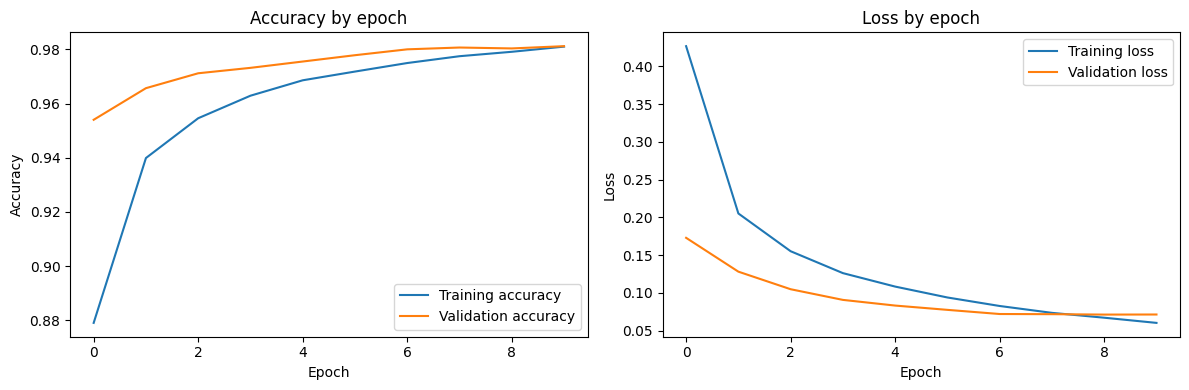

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history['accuracy'], label='Training accuracy')
axes[0].plot(history.history['val_accuracy'], label='Validation accuracy')
axes[0].set_title('Accuracy by epoch')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Accuracy')
axes[0].legend()

axes[1].plot(history.history['loss'], label='Training loss')
axes[1].plot(history.history['val_loss'], label='Validation loss')
axes[1].set_title('Loss by epoch')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Loss')
axes[1].legend()
plt.tight_layout()
plt.show()


## 8. Evaluate on the test set
The test set is separate from training and validation data. Report its metrics rather than assuming a target accuracy; results can vary slightly by environment and training run.


In [8]:
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy:.4%}')


Test loss: 0.0755
Test accuracy: 97.4700%


## 9. Classification report and confusion matrix
The classification report includes precision, recall, and F1-score for each digit. The confusion matrix shows which digit classes are most often confused.


              precision    recall  f1-score   support

           0     0.9779    0.9918    0.9848       980
           1     0.9860    0.9912    0.9886      1135
           2     0.9647    0.9787    0.9716      1032
           3     0.9646    0.9703    0.9674      1010
           4     0.9746    0.9776    0.9761       982
           5     0.9773    0.9675    0.9724       892
           6     0.9842    0.9749    0.9795       958
           7     0.9794    0.9718    0.9756      1028
           8     0.9536    0.9713    0.9624       974
           9     0.9846    0.9495    0.9667      1009

    accuracy                         0.9747     10000
   macro avg     0.9747    0.9745    0.9745     10000
weighted avg     0.9748    0.9747    0.9747     10000



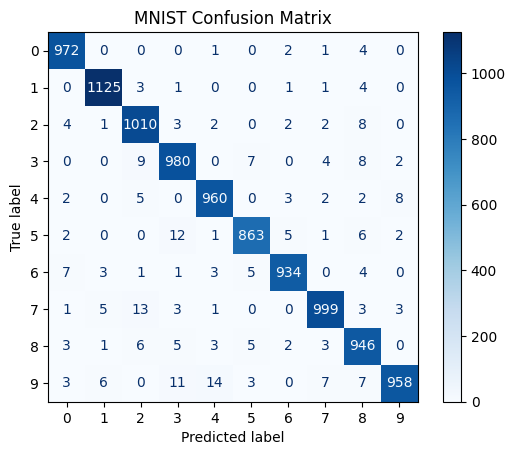

In [9]:
probabilities = model.predict(X_test, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print(classification_report(y_test, y_pred, digits=4))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=range(10))
disp.plot(cmap='Blues', values_format='d')
plt.title('MNIST Confusion Matrix')
plt.show()


## 10. Visualize predictions
Green titles indicate correct predictions; red titles indicate mistakes.


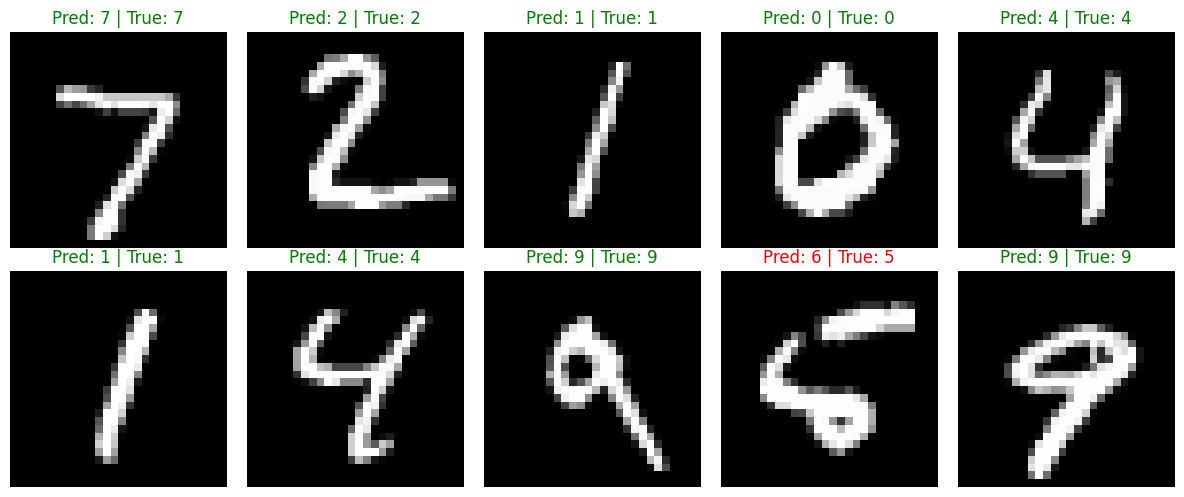

In [10]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i], cmap='gray')
    predicted = y_pred[i]
    actual = y_test[i]
    ax.set_title(f'Pred: {predicted} | True: {actual}', color=('green' if predicted == actual else 'red'))
    ax.axis('off')
plt.tight_layout()
plt.show()


## 11. Save the trained model
The model is saved in Keras format. The generated model file is an output of running this notebook and does not need to be committed to GitHub unless you specifically want to share it.


In [11]:
model.save('mnist_digit_classifier.keras')
print('Model saved as mnist_digit_classifier.keras')


Model saved as mnist_digit_classifier.keras


## Conclusion
This project demonstrates a complete deep-learning classification workflow: loading and exploring data, normalization, defining a neural network, training with backpropagation, evaluating on unseen data, and visualizing predictions. Possible extensions include comparing different hidden-layer sizes, adding a convolutional neural network (CNN), or creating a small web app for user-drawn digits.
